# 74. Search a 2D Matrix
**Difficulty:** 🟡 Medium · **Topic:** Binary Search · **Pattern:** [Sorted Search](README.md) · **LeetCode:** https://leetcode.com/problems/search-a-2d-matrix/

## 💡 Concepts

**Core concept(s):** **Binary search over a virtual 1-D array** — the matrix read row by row is one long sorted list, so search index `0 .. m·n - 1` and convert each index back to a cell.

**Why it applies here:**
- Each row is sorted, and each row starts above where the previous row ended.
- So reading the cells row by row (left to right, top to bottom) gives one sorted sequence of length `m·n`.
- The problem demands `O(log(m·n))`, which is exactly one binary search over that sequence.

**Key intuition:**
- You never build the flat list. You only need a way to read "element number `i`" of it.
- Element `i` lives at row `i // n`, column `i % n` (`n` = number of columns). `divmod(i, n)` gives both at once.
- With that mapping, the code is the plain binary search template.

---

### 📚 What is a 2-D Matrix (row-major order)?
- A **matrix** is a grid of `m` rows and `n` columns; `matrix[r][c]` is the cell in row `r`, column `c`.
- **Row-major order** numbers the cells row by row: row 0 gets indices `0 .. n-1`, row 1 gets `n .. 2n-1`, and so on.
- **Index mapping:** flat index `i` ↔ cell `(i // n, i % n)`; cell `(r, c)` ↔ flat index `r * n + c`. Both are `O(1)`.
- **In Python:** a list of lists; `divmod(i, n)` returns `(i // n, i % n)`.

### 📚 What is Binary Search?
- **Binary search** finds a value in a **sorted** sequence by repeatedly halving the part that can still contain it.
- Keep a search space `[lo, hi]`; look at `mid = (lo + hi) // 2`; equal → found, too small → `lo = mid + 1`, too big → `hi = mid - 1`; stop when `lo > hi`.
- **Invariant:** if the target exists, its index is inside `[lo, hi]`.
- **Complexity:** `O(log N)` time for `N` elements, `O(1)` extra space.
- **In Python:** written by hand, or `bisect.bisect_left` on a real list.

### 📚 What is a Staircase Search (two pointers on a sorted grid)?
- Start at the **top-right** corner. Everything to its left in that row is smaller; everything below it in that column is larger.
- If the corner is too big, the whole column below it is too big too: move **left**. If it is too small, the whole row to its left is too small: move **down**.
- Each step discards a whole row or a whole column, so it takes at most `m + n` steps → **`O(m + n)`** time, `O(1)` space.
- It only needs rows and columns to be sorted, so it also solves the harder "Search a 2D Matrix II", where rows do not chain into each other.

---

**Prerequisite knowledge:**
- The classic binary search loop (see [Binary Search](binary_search.ipynb)).
- Integer division `//` and remainder `%`.

## 📝 Problem

You are given an `m x n` integer matrix with two properties:
- each row is sorted in **non-decreasing** order;
- the first integer of each row is **greater than** the last integer of the previous row.

Given `target`, return `True` if it is in the matrix, else `False`. The solution must run in `O(log(m·n))` time.

**Example 1**
```
matrix = [[ 1,  3,  5,  7],
          [10, 11, 16, 20],
          [23, 30, 34, 60]],  target = 3   ->  True

read row by row: [1, 3, 5, 7, 10, 11, 16, 20, 23, 30, 34, 60]   <- one sorted list
                     ^ index 1 = row 1 // 4 = 0, col 1 % 4 = 1
```

**Example 2**
```
same matrix, target = 13   ->  False   (13 falls between 11 and 16)
```

**Constraints:** `1 <= m, n <= 100`, `-10⁴ <= matrix[i][j], target <= 10⁴`.

> Three approaches: scan every cell (`O(m·n)`), a staircase walk from the top-right corner (`O(m + n)`), and one binary search over the flattened index range (`O(log(m·n))`, the pattern template).

In [1]:
from typing import List
import random
from math import isqrt

### Approach 1 — Brute Force: check every cell

**Idea:**
1. Loop over every row, and every value in the row.
2. Return `True` on the first match; return `False` after the last cell.

**Time complexity:** `O(m·n)` — an absent target forces a look at every cell.

**Space complexity:** `O(1)`.

In [2]:
def search_matrix_brute(matrix: List[List[int]], target: int) -> bool:
    for row in matrix:
        for val in row:
            if val == target:      # ignores all the ordering: just looks
                return True
    return False

### Approach 2 — Better: staircase walk from the top-right corner

**Idea:**
1. Start at `r = 0`, `c = n - 1` (top-right).
2. If `matrix[r][c] == target`, done.
3. If it is **bigger** than the target, every cell below it in column `c` is bigger too: drop the column, `c -= 1`.
4. If it is **smaller**, every cell to its left in row `r` is smaller too: drop the row, `r += 1`.
5. Stop when you walk off the grid.

**Time complexity:** `O(m + n)` — each step removes one row or one column, and there are `m + n` of them.

**Space complexity:** `O(1)` — two indices.

> This uses less structure than the problem gives (it never uses "each row starts above the previous row's end"), which is why it cannot reach `O(log(m·n))`.

In [3]:
def search_matrix_staircase(matrix: List[List[int]], target: int) -> bool:
    m, n = len(matrix), len(matrix[0])
    r, c = 0, n - 1                       # top-right: the largest of its row, the smallest of its column
    while r < m and c >= 0:
        val = matrix[r][c]
        if val == target:
            return True
        if val > target:
            c -= 1                        # whole column c (from row r down) is too big
        else:
            r += 1                        # whole row r (from column c left) is too small
    return False

### Approach 3 — Binary search on the flattened index (optimal · pattern template)

**Idea:** the [Sorted Search](README.md) template over the virtual array of length `m·n`.
1. `lo = 0`, `hi = m·n - 1`.
2. While `lo <= hi`: `mid = (lo + hi) // 2`, and read its cell with `r, c = divmod(mid, n)`.
3. Equal → `True`; smaller → `lo = mid + 1`; bigger → `hi = mid - 1`.
4. Space empty → `False`.

**Time complexity:** `O(log(m·n))` — one binary search over `m·n` positions; each `divmod` is `O(1)`.

**Space complexity:** `O(1)` — the flat list is never built.

In [4]:
def search_matrix_flat(matrix: List[List[int]], target: int) -> bool:
    m, n = len(matrix), len(matrix[0])
    lo, hi = 0, m * n - 1                 # search space = every flat index, both ends inclusive
    while lo <= hi:
        mid = (lo + hi) // 2
        r, c = divmod(mid, n)             # flat index -> (row, column): row = mid // n, col = mid % n
        val = matrix[r][c]
        if val == target:
            return True
        if val < target:
            lo = mid + 1                  # target is later in row-major order
        else:
            hi = mid - 1                  # target is earlier in row-major order
    return False

In [5]:
# Correctness check
M = [[1, 3, 5, 7], [10, 11, 16, 20], [23, 30, 34, 60]]
tests = [
    (M, 3, True),           # LeetCode example 1
    (M, 13, False),         # LeetCode example 2: between 11 and 16
    (M, 1, True),           # top-left corner (first flat index)
    (M, 60, True),          # bottom-right corner (last flat index)
    (M, 7, True),           # end of a row
    (M, 10, True),          # start of a row
    (M, 0, False),          # smaller than everything
    (M, 61, False),         # larger than everything
    ([[1]], 1, True),       # 1 x 1, present
    ([[1]], 2, False),      # 1 x 1, absent
    ([[1, 3]], 3, True),    # single row
    ([[1], [3]], 3, True),  # single column
]
for matrix, target, exp in tests:
    a = search_matrix_brute(matrix, target)
    b = search_matrix_staircase(matrix, target)
    c = search_matrix_flat(matrix, target)
    print(f"{str(matrix):46} target={target:>3} -> {c}")
    assert a == b == c == exp, f"mismatch on {matrix}, {target}: brute={a} stair={b} flat={c}"

# Randomised cross-check: all three agree on random valid matrices (non-decreasing rows that chain)
rng = random.Random(74)
for _ in range(500):
    m, n = rng.randint(1, 6), rng.randint(1, 6)
    flat = sorted(rng.randint(-30, 30) for _ in range(m * n))
    for i in range(1, m):                     # make each row start strictly above the previous row's end
        if flat[i * n] <= flat[i * n - 1]:
            shift = flat[i * n - 1] + 1 - flat[i * n]
            for j in range(i * n, m * n):
                flat[j] += shift
    matrix = [flat[i * n:(i + 1) * n] for i in range(m)]
    target = rng.randint(-35, 60)
    assert search_matrix_brute(matrix, target) == search_matrix_staircase(matrix, target) == search_matrix_flat(matrix, target), (matrix, target)
print("500 random matrices: all three approaches agree")

print("\nAll tests passed")

[[1, 3, 5, 7], [10, 11, 16, 20], [23, 30, 34, 60]] target=  3 -> True
[[1, 3, 5, 7], [10, 11, 16, 20], [23, 30, 34, 60]] target= 13 -> False
[[1, 3, 5, 7], [10, 11, 16, 20], [23, 30, 34, 60]] target=  1 -> True
[[1, 3, 5, 7], [10, 11, 16, 20], [23, 30, 34, 60]] target= 60 -> True
[[1, 3, 5, 7], [10, 11, 16, 20], [23, 30, 34, 60]] target=  7 -> True
[[1, 3, 5, 7], [10, 11, 16, 20], [23, 30, 34, 60]] target= 10 -> True
[[1, 3, 5, 7], [10, 11, 16, 20], [23, 30, 34, 60]] target=  0 -> False
[[1, 3, 5, 7], [10, 11, 16, 20], [23, 30, 34, 60]] target= 61 -> False
[[1]]                                          target=  1 -> True
[[1]]                                          target=  2 -> False
[[1, 3]]                                       target=  3 -> True
[[1], [3]]                                     target=  3 -> True
500 random matrices: all three approaches agree

All tests passed


## ⏱️ Empirically Checking the Complexities

Big-O can't be read off a function directly, but it can be **measured**. We time each approach on matrices with a growing number of cells `N = m·n` and read the **doubling ratio** — how much runtime grows when `N` doubles.

| Theoretical (square matrix, `m = n = √N`) | Ratio when `N` → `2N` |
|-------------|-----------------------|
| `O(log N)` — flat binary search | ≈ **1×** |
| `O(m + n) = O(√N)` — staircase  | ≈ **1.4×** |
| `O(N)` — every cell             | ≈ **2×** |

**Worst case:** a square matrix of even numbers and an **odd** target just below the bottom-left cell. It is absent, so the brute force reads all `N` cells; the staircase walks down the whole last column and then left along the whole last row (`m + n` steps); the flat binary search runs its full `log₂ N` halvings. The two fast approaches finish in microseconds, so `repeats=5` keeps the best of five runs.


every cell O(m*n)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
    62500 |       0.67 |           n/a
   125000 |       1.37 |         2.04x
   250000 |       3.01 |         2.19x
   500000 |       6.75 |         2.24x

staircase O(m+n)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
    62500 |       0.03 |           n/a
   125000 |       0.05 |         1.56x
   250000 |       0.07 |         1.49x


   500000 |       0.10 |         1.46x



flat binary search O(log(m*n))
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
    62500 |       0.00 |           n/a
   125000 |       0.00 |         1.21x
   250000 |       0.00 |         1.07x
   500000 |       0.00 |         1.03x

Ratios per doubling: ~1x=>constant/log, ~2x=>linear or n log n, ~4x=>quadratic, ~8x=>cubic.


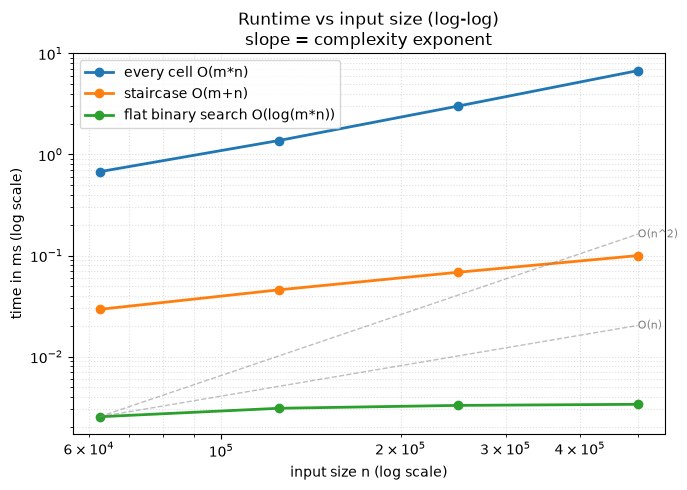

{'every cell O(m*n)': [0.6748751038685441,
  1.3741659931838512,
  3.013332956470549,
  6.747125065885484],
 'staircase O(m+n)': [0.029333052225410938,
  0.04579196684062481,
  0.06837490946054459,
  0.09983393829315901],
 'flat binary search O(log(m*n))': [0.0025420449674129486,
  0.0030830269679427147,
  0.0032919924706220627,
  0.003374996595084667]}

In [6]:
import os, sys
_root = os.getcwd()
for _ in range(5):
    if os.path.exists(os.path.join(_root, "bench_utils.py")):
        break
    _root = os.path.dirname(_root)
if _root not in sys.path:
    sys.path.insert(0, _root)
from bench_utils import benchmark

def make_worst_case(N):
    m = isqrt(N)                              # square-ish: m rows ...
    n = N // m                                # ... and n columns
    matrix = [[2 * (r * n + c) for c in range(n)] for r in range(m)]   # 0, 2, 4, ... row by row
    target = matrix[m - 1][0] - 1             # odd, just below the bottom-left cell: absent
    return (matrix, target)

solutions = {
    "every cell O(m*n)": search_matrix_brute,
    "staircase O(m+n)": search_matrix_staircase,
    "flat binary search O(log(m*n))": search_matrix_flat,
}
sizes = [62_500, 125_000, 250_000, 500_000]

benchmark(solutions, make_worst_case, sizes, repeats=5, plot=True)

## 🧩 Patterns Learned

- **Pattern:** [Sorted Search](README.md) — the template unchanged over the index range `0 .. m·n - 1`; the only new line is `r, c = divmod(mid, n)` to read the "virtual" element.
- **Flatten without copying:** when a structure is sorted in some reading order, binary search the *positions* and map each position to its storage location in `O(1)`.
- **Staircase alternative:** from the top-right corner, each comparison drops a row or a column — `O(m + n)`. Reach for it when rows and columns are sorted but rows do **not** chain (Search a 2D Matrix II); there the flat search is wrong.
- **Signal:** "each row sorted" **and** "first of each row > last of previous row", plus an `O(log(m·n))` requirement.
- **Related problems:** Binary Search, Search a 2D Matrix II (staircase), Kth Smallest Element in a Sorted Matrix, Time Based Key-Value Store.
- **Common pitfalls:**
  1. `divmod(mid, m)` (rows) instead of `divmod(mid, n)` (columns) — wrong cell on any non-square matrix.
  2. Two binary searches (find the row, then search it) work in `O(log m + log n)` but have more boundary cases than one flat search.
  3. Using the flat search on a matrix where rows do not chain — the flattened list is then not sorted.